In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

In [3]:
df = pd.read_csv("Student_Performance.csv")

print("Dataset:")
print(df.head())

Dataset:
   Hours Studied  Previous Scores Extracurricular Activities  Sleep Hours  \
0              7               99                        Yes            9   
1              4               82                         No            4   
2              8               51                        Yes            7   
3              5               52                        Yes            5   
4              7               75                         No            8   

   Sample Question Papers Practiced  Performance Index  
0                                 1               91.0  
1                                 2               65.0  
2                                 2               45.0  
3                                 2               36.0  
4                                 5               66.0  


In [4]:
print("\nDataset Information:")
print(df.info())



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        10000 non-null  str    
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  10000 non-null  int64  
 5   Performance Index                 10000 non-null  float64
dtypes: float64(1), int64(4), str(1)
memory usage: 468.9 KB
None


In [5]:
X_simple = df[["Hours Studied"]]
y = df["Performance Index"]


In [6]:
X_multiple = df[
    ["Hours Studied", "Previous Scores",
     "Sleep Hours", "Sample Question Papers Practiced"]
]


In [7]:
X_train_s, X_test_s, y_train, y_test = train_test_split(
    X_simple, y, test_size=0.2, random_state=42
)

X_train_m, X_test_m, _, _ = train_test_split(
    X_multiple, y, test_size=0.2, random_state=42
)

In [8]:
simple_model = LinearRegression()
simple_model.fit(X_train_s, y_train)

simple_predictions = simple_model.predict(X_test_s)

print("\n--- Simple Linear Regression ---")
print("Intercept:", simple_model.intercept_)
print("Coefficient:", simple_model.coef_[0])
print("R2 Score:", r2_score(y_test, simple_predictions))
print("RMSE:", np.sqrt(
    mean_squared_error(y_test, simple_predictions)
))


--- Simple Linear Regression ---
Intercept: 41.43663482653601
Coefficient: 2.7843004411707217
R2 Score: 0.13160425385996788
RMSE: 17.93919001285204


In [9]:
multiple_model = LinearRegression()
multiple_model.fit(X_train_m, y_train)

multiple_predictions = multiple_model.predict(X_test_m)

print("\n--- Multiple Linear Regression ---")
print("Intercept:", multiple_model.intercept_)
print("Coefficients:", multiple_model.coef_)
print("R2 Score:", r2_score(y_test, multiple_predictions))
print("RMSE:", np.sqrt(
    mean_squared_error(y_test, multiple_predictions)
))


--- Multiple Linear Regression ---
Intercept: -33.60206732749263
Coefficients: [2.85289351 1.01703572 0.47331832 0.19172629]
R2 Score: 0.9887144552384186
RMSE: 2.0450562130645253


In [10]:
new_student_simple = pd.DataFrame({
    "Hours Studied": [6]
})

In [11]:
new_student_multiple = pd.DataFrame({
    "Hours Studied": [6],
    "Previous Scores": [80],
    "Sleep Hours": [7],
    "Sample Question Papers Practiced": [4]
})

print("\nPredicted Performance using Simple Regression:",
      simple_model.predict(new_student_simple)[0])

print("Predicted Performance using Multiple Regression:",
      multiple_model.predict(new_student_multiple)[0])



Predicted Performance using Simple Regression: 58.142437473560335
Predicted Performance using Multiple Regression: 68.95828440998102


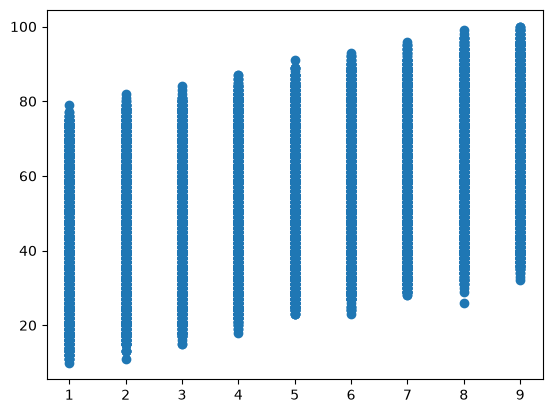

In [12]:
plt.scatter(
    df["Hours Studied"],
    y,
    label="Actual Performance"
)
plt.plot(
    df["Hours Studied"],
    simple_model.predict(X_simple),
    color="red",
    label="Regression Line"
)
plt.xlabel("Hours Studied")
plt.ylabel("Performance Index")
plt.title("Simple Linear Regression")
plt.legend()
plt.show()


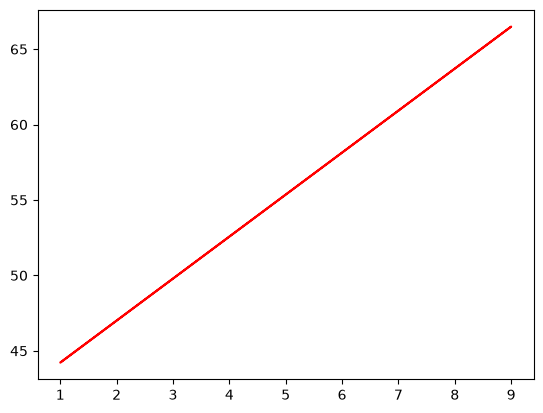

C:\Users\KRUTIKA SHIVANAND\AppData\Local\Temp\ipykernel_5008\3450294031.py:4: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


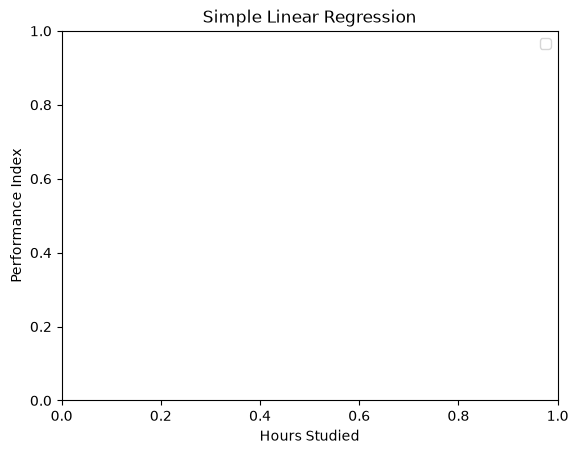

In [ ]:




# Step 7: Plot Simple Linear Regression




